# 6001CMD — UCI Bike Sharing Analysis

This notebook records the reproducible analysis used as evidence for Tasks 1–4. Keep written interpretation in your own words and connect every output to the coursework argument.

## 1. Setup and data loading

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'hour.csv'
FIGURES_DIR = PROJECT_ROOT / 'figures'
TABLES_DIR = PROJECT_ROOT / 'tables'
FIGURES_DIR.mkdir(exist_ok=True)
TABLES_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from analysis import audit_data, load_data

sns.set_theme(style='whitegrid', context='notebook')

In [4]:
df = load_data(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1] - 1} original columns')
display(df.head())

Shape: 17,379 rows x 17 original columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


## 2. Initial data-quality audit

The audit tests missing values, duplicate records, continuity of the hourly timeline, target leakage, target skewness, and potential redundancy between `temp` and `atemp`.

In [5]:
audit = pd.Series(audit_data(df), name='value').to_frame()
display(audit)

,value
rows,17379
original_columns,17
start_timestamp,2011-01-01 00:00:00
end_timestamp,2012-12-31 23:00:00
total_missing_values,0
exact_duplicate_rows,0
duplicate_timestamps,0
missing_hourly_timestamps,165
target_identity_holds,True
cnt_mean,189.463088


## 3. Target distribution

Interpret the chart rather than only describing its appearance. In particular, discuss right skew, genuine demand peaks, and why automatic outlier deletion could remove meaningful observations.

C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


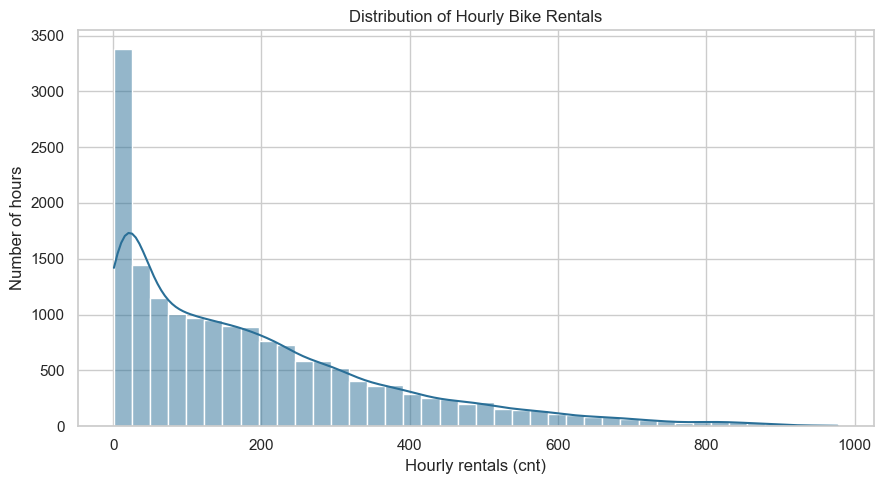

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x='cnt', bins=40, kde=True, color='#2A6F97', ax=ax)
ax.set(title='Distribution of Hourly Bike Rentals', xlabel='Hourly rentals (cnt)', ylabel='Number of hours')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'cnt_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Leakage check

`casual` and `registered` must be excluded from the model because together they exactly reconstruct the target `cnt`. `instant` is also excluded because it is a row identifier.

In [7]:
leakage_identity = (df['cnt'] == df['casual'] + df['registered']).all()
print('cnt equals casual + registered for every row:', leakage_identity)
model_features = [c for c in df.columns if c not in {'cnt', 'casual', 'registered', 'instant', 'timestamp', 'dteday'}]
print('Candidate predictor columns:', model_features)

cnt equals casual + registered for every row: True
Candidate predictor columns: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


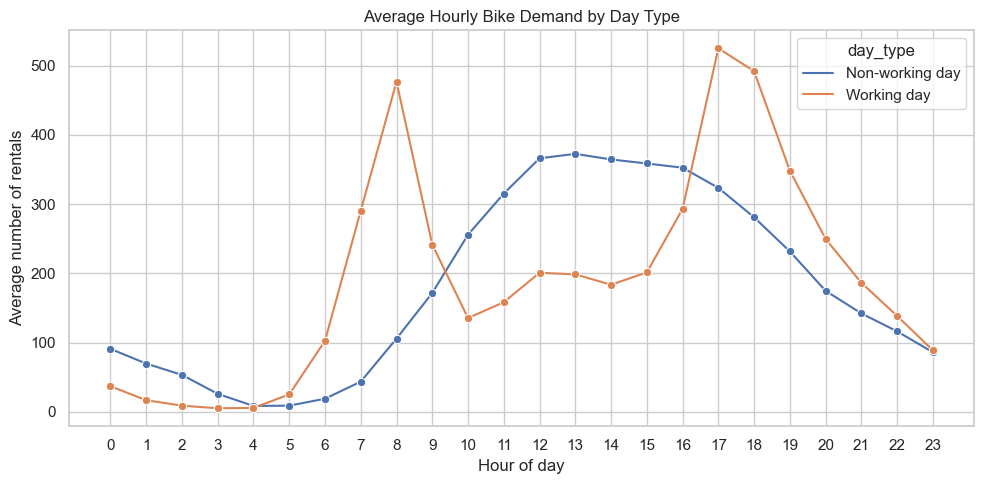

In [8]:
hourly = df.groupby(['workingday', 'hr'], as_index=False)['cnt'].mean()
hourly['day_type'] = hourly['workingday'].map({
    0: 'Non-working day',
    1: 'Working day'
})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=hourly, x='hr', y='cnt',
    hue='day_type', marker='o', ax=ax
)
ax.set(
    title='Average Hourly Bike Demand by Day Type',
    xlabel='Hour of day',
    ylabel='Average number of rentals',
    xticks=range(24)
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'mean_demand_by_hour.png',
            dpi=300, bbox_inches='tight')
plt.show()

## Task 1: Business context and ML objective

Capital Bikeshare’s hourly rental activity changes substantially throughout the day. In the exploratory chart, working days show pronounced peaks around 08:00 and 17:00–18:00, while non-working-day rentals are more concentrated from midday to late afternoon. Forecasting these changes could help the operator plan overall bike availability and staffing. However, the dataset contains system-wide hourly totals rather than station-level records, so it cannot identify how many bikes should be moved to a particular station.

This project uses hour.csv from the UCI Bike Sharing Dataset, which records Capital Bikeshare rentals during 2011–2012 (Fanaee-T, 2013). The file contains 17,379 hourly observations and 17 original variables. Calendar information, such as hour, month, holiday status and working-day status, may help explain recurring demand patterns. Weather variables provide additional context. The target, cnt, is the number of rentals recorded in an hour. Because historical examples include both predictors and a known numeric target, the main task is supervised regression of hourly rental counts.

The instant field is a record identifier and is excluded. The casual and registered counts are also excluded: their sum equals cnt in every observation, so using them would reveal the answer to the model. For a genuine advance forecast, observed weather conditions would need to be replaced with weather forecasts available at prediction time. A calendar-only model would therefore provide a practical baseline before assessing whether forecast weather improves accuracy. Model evaluation should preserve time order so that future observations are never used to predict the past.

In [9]:
variable_profile = pd.DataFrame({
    'data_type': df.drop(columns='timestamp').dtypes.astype(str),
    'distinct_values': df.drop(columns='timestamp').nunique(),
    'missing_values': df.drop(columns='timestamp').isna().sum()
})

display(variable_profile)
variable_profile.to_csv(TABLES_DIR / 'variable_profile.csv',
                        index_label='variable')

,data_type,distinct_values,missing_values
instant,int64,17379,0
dteday,object,731,0
season,int64,4,0
yr,int64,2,0
mnth,int64,12,0
hr,int64,24,0
holiday,int64,2,0
weekday,int64,7,0
workingday,int64,2,0
weathersit,int64,4,0


## Task 2: Supervised versus unsupervised learning
Supervised learning uses historical data with known rental counts (cnt) to predict future hourly demand. Unsupervised learning groups similar historical patterns without a prediction target, but it does not directly forecast how many bikes will be rented.
| Method | Strength | Limitation | Relative cost |
|---|---|---|---|
| Poisson regression ([Nelder & Wedderburn, 1972](https://academic.oup.com/jrsssa/article/135/3/370/7110572)) | Interpretable baseline for rental counts | May miss complex interactions | Low |
| Random Forest ([Breiman, 2001](https://doi.org/10.1023/A:1010933404324)) | Captures nonlinear patterns | Harder to explain | Medium |
| Gradient Boosting ([Friedman, 2001](https://doi.org/10.1214/aos/1013203451)) | Flexible prediction model | Needs careful tuning | Higher |
| K-means ([MacQueen, 1967](https://digicoll.lib.berkeley.edu/record/113015/files/math_s5_v1_article-17.pdf)) | Finds groups of similar historical days | Does not directly predict `cnt` | Low–medium |

**Recommendation:** Use supervised regression as the main approach because the goal is a numerical rental forecast. Use clustering only to explore historical demand patterns.

## Task 3: Data quality


Expected hours: 17544
Missing hours: 165


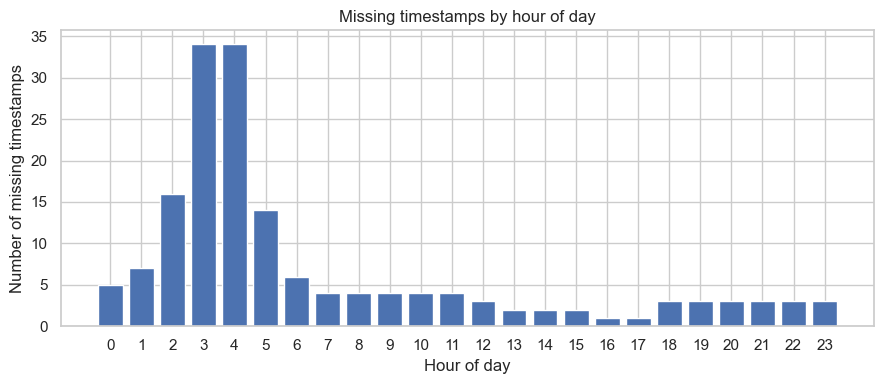

In [10]:
expected = pd.date_range(
    df['timestamp'].min(), df['timestamp'].max(), freq='h'
)
missing_hours = expected.difference(df['timestamp'])

missing_by_hour = (
    pd.Series(missing_hours.hour)
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

print('Expected hours:', len(expected))
print('Missing hours:', len(missing_hours))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_by_hour.index, missing_by_hour.values)
ax.set(
    title='Missing timestamps by hour of day',
    xlabel='Hour of day',
    ylabel='Number of missing timestamps',
    xticks=range(24)
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'missing_hours_by_hour.png', dpi=300)
plt.show()

The dataset has no empty cells, but 165 of 17,544 expected hourly timestamps are absent (0.94%). Most gaps occur overnight. Their cause is uncertain, so treating every missing hour as zero rentals could bias the analysis.


Upper IQR threshold: 642.5
Hours above threshold: 505
Percentage: 2.91


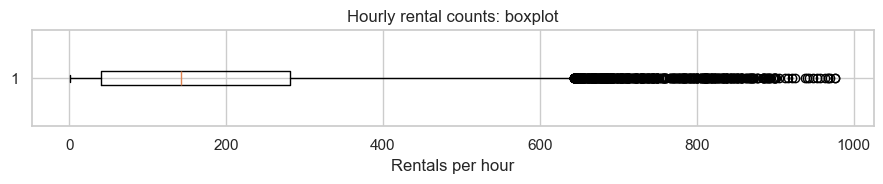

In [11]:
q1, q3 = df['cnt'].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
high_count = (df['cnt'] > upper).sum()

print('Upper IQR threshold:', upper)
print('Hours above threshold:', high_count)
print('Percentage:', round(high_count / len(df) * 100, 2))

fig, ax = plt.subplots(figsize=(9, 2))
ax.boxplot(df['cnt'], vert=False)
ax.set(title='Hourly rental counts: boxplot',
       xlabel='Rentals per hour')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'cnt_boxplot.png', dpi=300)
plt.show()

In [12]:
high_demand = df[df['cnt'] > upper]

display(
    high_demand['hr'].value_counts()
    .head(10)
    .rename('high_demand_hours')
    .to_frame()
)

display(
    high_demand[['dteday', 'hr', 'workingday', 'cnt']]
    .sort_values('cnt', ascending=False)
    .head(5)
)

,high_demand_hours
hr,
17,153
18,129
8,127
13,23
12,17
14,15
19,14
15,13
16,12


,dteday,hr,workingday,cnt
14773,2012-09-12,18,1,977
14964,2012-09-20,17,1,976
14748,2012-09-11,17,1,970
14725,2012-09-10,18,1,968
15084,2012-09-25,17,1,967


The IQR rule flagged 505 high-count hours (2.91%). Of these, 409 occurred at 08:00, 17:00 or 18:00, consistent with commuter peaks. They will be retained because removing them could weaken predictions during periods of high demand.

In [13]:
weather_counts = df['weathersit'].value_counts().sort_index()
display(pd.DataFrame({
    'hours': weather_counts,
    'percent': (weather_counts / len(df) * 100).round(2)
}))

display(df[['temp', 'atemp']].corr().round(3))

,hours,percent
weathersit,,
1,11413,65.67
2,4544,26.15
3,1419,8.17
4,3,0.02


,temp,atemp
temp,1.000,0.988
atemp,0.988,1.000


## Task 4: Preprocessing strategy

In [14]:
model_df = df.sort_values('timestamp').reset_index(drop=True)

excluded = ['cnt', 'casual', 'registered',
            'instant', 'dteday', 'timestamp']
X = model_df.drop(columns=excluded)
y = model_df['cnt']

train_end = int(len(model_df) * 0.70)
val_end = int(len(model_df) * 0.85)

for name, start, end in [
    ('Train', 0, train_end),
    ('Validation', train_end, val_end),
    ('Test', val_end, len(model_df))
]:
    print(
        name, end - start, 'rows:',
        model_df.loc[start, 'timestamp'],
        'to',
        model_df.loc[end - 1, 'timestamp']
    )

print('Candidate features:', list(X.columns))

Train 12165 rows: 2011-01-01 00:00:00 to 2012-05-27 01:00:00
Validation 2607 rows: 2012-05-27 02:00:00 to 2012-09-12 16:00:00
Test 2607 rows: 2012-09-12 17:00:00 to 2012-12-31 23:00:00
Candidate features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [15]:
calendar_cols = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday'
]
weather_cols = [
    'weathersit', 'temp', 'atemp', 'hum', 'windspeed'
]

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print('Calendar-only features:', calendar_cols)
print('Weather features requiring forecasts:', weather_cols)
print('Train / validation / test shapes:',
      X_train.shape, X_val.shape, X_test.shape)

Calendar-only features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday']
Weather features requiring forecasts: ['weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Train / validation / test shapes: (12165, 12) (2607, 12) (2607, 12)


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ['season', 'mnth', 'hr', 'weekday', 'weathersit']
continuous_cols = ['temp', 'hum', 'windspeed']
binary_cols = ['yr', 'holiday', 'workingday']
selected_cols = categorical_cols + continuous_cols + binary_cols

preprocessor = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='ignore'),
     categorical_cols),
    ('numbers', StandardScaler(), continuous_cols),
    ('binary', 'passthrough', binary_cols)
])

X_train_ready = preprocessor.fit_transform(X_train[selected_cols])
X_val_ready = preprocessor.transform(X_val[selected_cols])
X_test_ready = preprocessor.transform(X_test[selected_cols])

print('Before encoding:', X_train[selected_cols].shape)
print('After encoding:', X_train_ready.shape)
print('Validation:', X_val_ready.shape)
print('Test:', X_test_ready.shape)

Before encoding: (12165, 11)
After encoding: (12165, 57)
Validation: (2607, 57)
Test: (2607, 57)


In [17]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

calendar_preprocessor = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='ignore'),
     ['season', 'mnth', 'hr', 'weekday']),
    ('binary', 'passthrough',
     ['yr', 'holiday', 'workingday'])
])

train_calendar = calendar_preprocessor.fit_transform(
    X_train[calendar_cols]
)
val_calendar = calendar_preprocessor.transform(
    X_val[calendar_cols]
)

calendar_model = Ridge(alpha=10, solver='lsqr')
calendar_model.fit(train_calendar, y_train)

weather_model = Ridge(alpha=10, solver='lsqr')
weather_model.fit(X_train_ready, y_train)

def evaluate(name, predictions):
    predictions = np.maximum(predictions, 0)
    return {
        'model': name,
        'MAE': mean_absolute_error(y_val, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_val, predictions))
    }

results = pd.DataFrame([
    evaluate('Calendar only', calendar_model.predict(val_calendar)),
    evaluate('Calendar + observed weather',
             weather_model.predict(X_val_ready))
])

display(results.round(2))

,model,MAE,RMSE
0,Calendar only,116.52,144.75
1,Calendar + observed weather,111.10,142.34


Categorical variables were one-hot encoded, continuous weather variables were standardised, and binary flags were retained. The transformations were fitted on training data only. On the validation set, adding observed weather to a Ridge baseline reduced MAE from 116.52 to 111.10 and RMSE from 144.75 to 142.34. This modest gain is an optimistic estimate for advance forecasting because actual future weather would need to be replaced by forecasts. High-demand observations were retained, while absent timestamps were documented rather than automatically filled with zero.